In [7]:
import numpy as np

In [7]:
data = np.loadtxt("./generated_hls/results.txt",delimiter=None, dtype=np.float64)
# data = np.loadtxt("./utilities/results.txt",delimiter=None, dtype=np.float64)

In [8]:
data

array([-0.00756836, -0.0102539 , -0.0114746 , ..., -0.015625  ,
       -0.0129395 , -0.010498  ])

In [9]:
predictions = data.reshape(-1,5)
# predictions = data.reshape(-1,5)[0:990]

In [10]:
predictions

array([[-0.00756836, -0.0102539 , -0.0114746 , -0.0114746 , -0.0112305 ],
       [-0.010498  , -0.00537109, -0.0136719 , -0.0114746 , -0.0109863 ],
       [-0.00952148, -0.010498  , -0.00610352, -0.0114746 , -0.0131836 ],
       ...,
       [-0.00732422, -0.0112305 , -0.00878906, -0.0112305 , -0.0107422 ],
       [-0.0102539 , -0.00756836, -0.0131836 , -0.0112305 , -0.0107422 ],
       [-0.0078125 , -0.00512695, -0.015625  , -0.0129395 , -0.010498  ]])

In [11]:
argmax_indices = np.argmax(predictions, axis=1)

# Create one-hot encoded vectors
one_hot_vectors = np.eye(5)[argmax_indices]

In [12]:
one_hot_vectors

array([[1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       [0., 0., 1., 0., 0.],
       ...,
       [1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       [0., 1., 0., 0., 0.]])

In [13]:
# true_labels = np.load("./datasets/mps_data/y_N16.npy")
true_labels = np.load("./datasets/mps_data/y_N4.npy")#[0:990]

In [14]:
true_labels

array([[0., 1., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       [0., 0., 1., 0., 0.],
       ...,
       [1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1.],
       [0., 1., 0., 0., 0.]])

In [15]:
# Convert one-hot encoded vectors to class labels
y_true_labels = np.argmax(true_labels, axis=1)
y_pred_labels = np.argmax(predictions, axis=1)

# Compare accuracy using NumPy
accuracy_np = np.mean(y_true_labels == y_pred_labels)
print(f"Accuracy (NumPy): {accuracy_np:.4f}")

Accuracy (NumPy): 0.4430


In [16]:
#In case you want to convert .npy files

from pathlib import Path
import numpy as np

def save_npy_as_bin(npy_file: Path, output_file: Path) -> None:
        print(f"Processing .npy file: {npy_file}")
        array_data = np.load(npy_file).flatten()
        array_data.astype(np.float64).tofile(output_file)
        print(f"Saved .npy as binary: {output_file}")

def save_npy_as_dat( npy_file: Path, results_dat: Path) -> None:
        data = np.load(npy_file).flatten()
        np.savetxt(results_dat, data, fmt="%s")

In [101]:
# save_npy_as_bin('./datasets/mps_data/X_N4_embedded.npy','./datasets/mps_data/X_N4_embedded.bin')
# save_npy_as_dat('./datasets/mps_data/X_N4_embedded.npy','./datasets/mps_data/X_N4_embedded.txt')

## MPS16

In [2]:
import os
from pathlib import Path

mps16_quantization_folder = Path("./mps16_qresults")
mps16_results_list = list(mps16_quantization_folder.glob("*.txt"))
mps16_results_list.sort()

In [7]:

# results_list

In [28]:
def calc_accuracy(results_file: Path, true_labels_file: Path,  sample_size: int = 1000) -> tuple:
    
    word_width = results_file.stem.split('_')[0].replace('bit','')
    int_bits = results_file.stem.split('_')[1].replace('int','')
    
    # print(f"Calculating accuracy for results file: {results_file}, word width: {word_width}, int bits: {int_bits}")
    pass
    # Load the results and true labels
    predictions = np.loadtxt(results_file, delimiter=None, dtype=np.float64).reshape(-1, 5)
    true_labels = np.load(true_labels_file).reshape(-1, 5)
    
    print(f"Predictions shape: {predictions.shape}, True labels shape: {true_labels.shape}")

    # Convert one-hot encoded vectors to class labels
    y_true_labels = np.argmax(true_labels, axis=1)[:sample_size]
    y_pred_labels = np.argmax(predictions, axis=1)[:sample_size]

    # print(y_true_labels[:5])
    # print(y_pred_labels[:5])

    # Calculate accuracy
    accuracy = np.mean(y_true_labels == y_pred_labels)
    return int(word_width), int(int_bits), accuracy

In [9]:
ww_list = []
iw_list = []
accuracy_list = []
mps16_labels_file = Path("./datasets/mps_data/y_N16.npy")
for results_file in mps16_results_list:
    word_width, int_bits, accuracy = calc_accuracy(results_file, mps16_labels_file)
    ww_list.append(word_width)
    iw_list.append(int_bits)
    accuracy_list.append(accuracy)
    print(f"Accuracy for {word_width}_{int_bits}: {accuracy:.4f}")

Accuracy for 16_4: 0.6140
Accuracy for 16_5: 0.6220
Accuracy for 16_6: 0.5870
Accuracy for 16_7: 0.5110
Accuracy for 16_8: 0.4280
Accuracy for 16_9: 0.4000
Accuracy for 17_4: 0.6180
Accuracy for 17_5: 0.6410
Accuracy for 17_6: 0.6470
Accuracy for 17_7: 0.6020
Accuracy for 17_8: 0.5290
Accuracy for 17_9: 0.4390
Accuracy for 18_4: 0.6150
Accuracy for 18_5: 0.6490
Accuracy for 18_6: 0.6710
Accuracy for 18_7: 0.6650
Accuracy for 18_8: 0.6230
Accuracy for 18_9: 0.5470
Accuracy for 19_4: 0.6140
Accuracy for 19_5: 0.6430
Accuracy for 19_6: 0.6730
Accuracy for 19_7: 0.6970
Accuracy for 19_8: 0.6860
Accuracy for 19_9: 0.6380
Accuracy for 20_4: 0.6130
Accuracy for 20_5: 0.6450
Accuracy for 20_6: 0.6720
Accuracy for 20_7: 0.6930
Accuracy for 20_8: 0.7110
Accuracy for 20_9: 0.7000
Accuracy for 21_4: 0.6110
Accuracy for 21_5: 0.6460
Accuracy for 21_6: 0.6740
Accuracy for 21_7: 0.6920
Accuracy for 21_8: 0.7080
Accuracy for 21_9: 0.7270


In [4]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from collections import defaultdict


def plot_accuracy_vs_integer_bits(ww_list, iw_list, accuracy_list, dataset_name="MPS16"):
    # Group data by word width
    data = defaultdict(lambda: {"int": [], "acc": []})

    for w, i, a in zip(ww_list, iw_list, accuracy_list):
        data[w]["int"].append(i)
        data[w]["acc"].append(a)

    # Plot
    plt.figure(figsize=(16,14))

    for w in sorted(data.keys()):
        # Sort by integer bits so the line is drawn correctly
        x, y = zip(*sorted(zip(data[w]["int"], data[w]["acc"])))
        plt.plot(x, y, marker='o', linewidth=2, label=f'Word Width = {w}')

    ax = plt.gca()
    ax.yaxis.set_major_locator(MultipleLocator(0.02))
    ax.xaxis.set_major_locator(MultipleLocator(1))
    plt.xlabel("Integer Bits")
    plt.ylabel("Accuracy")
    plt.title(f"Accuracy vs Integer Bits ({dataset_name})")
    plt.grid(True)
    plt.legend(title="Word Width")
    plt.tight_layout()
    plt.show()
    



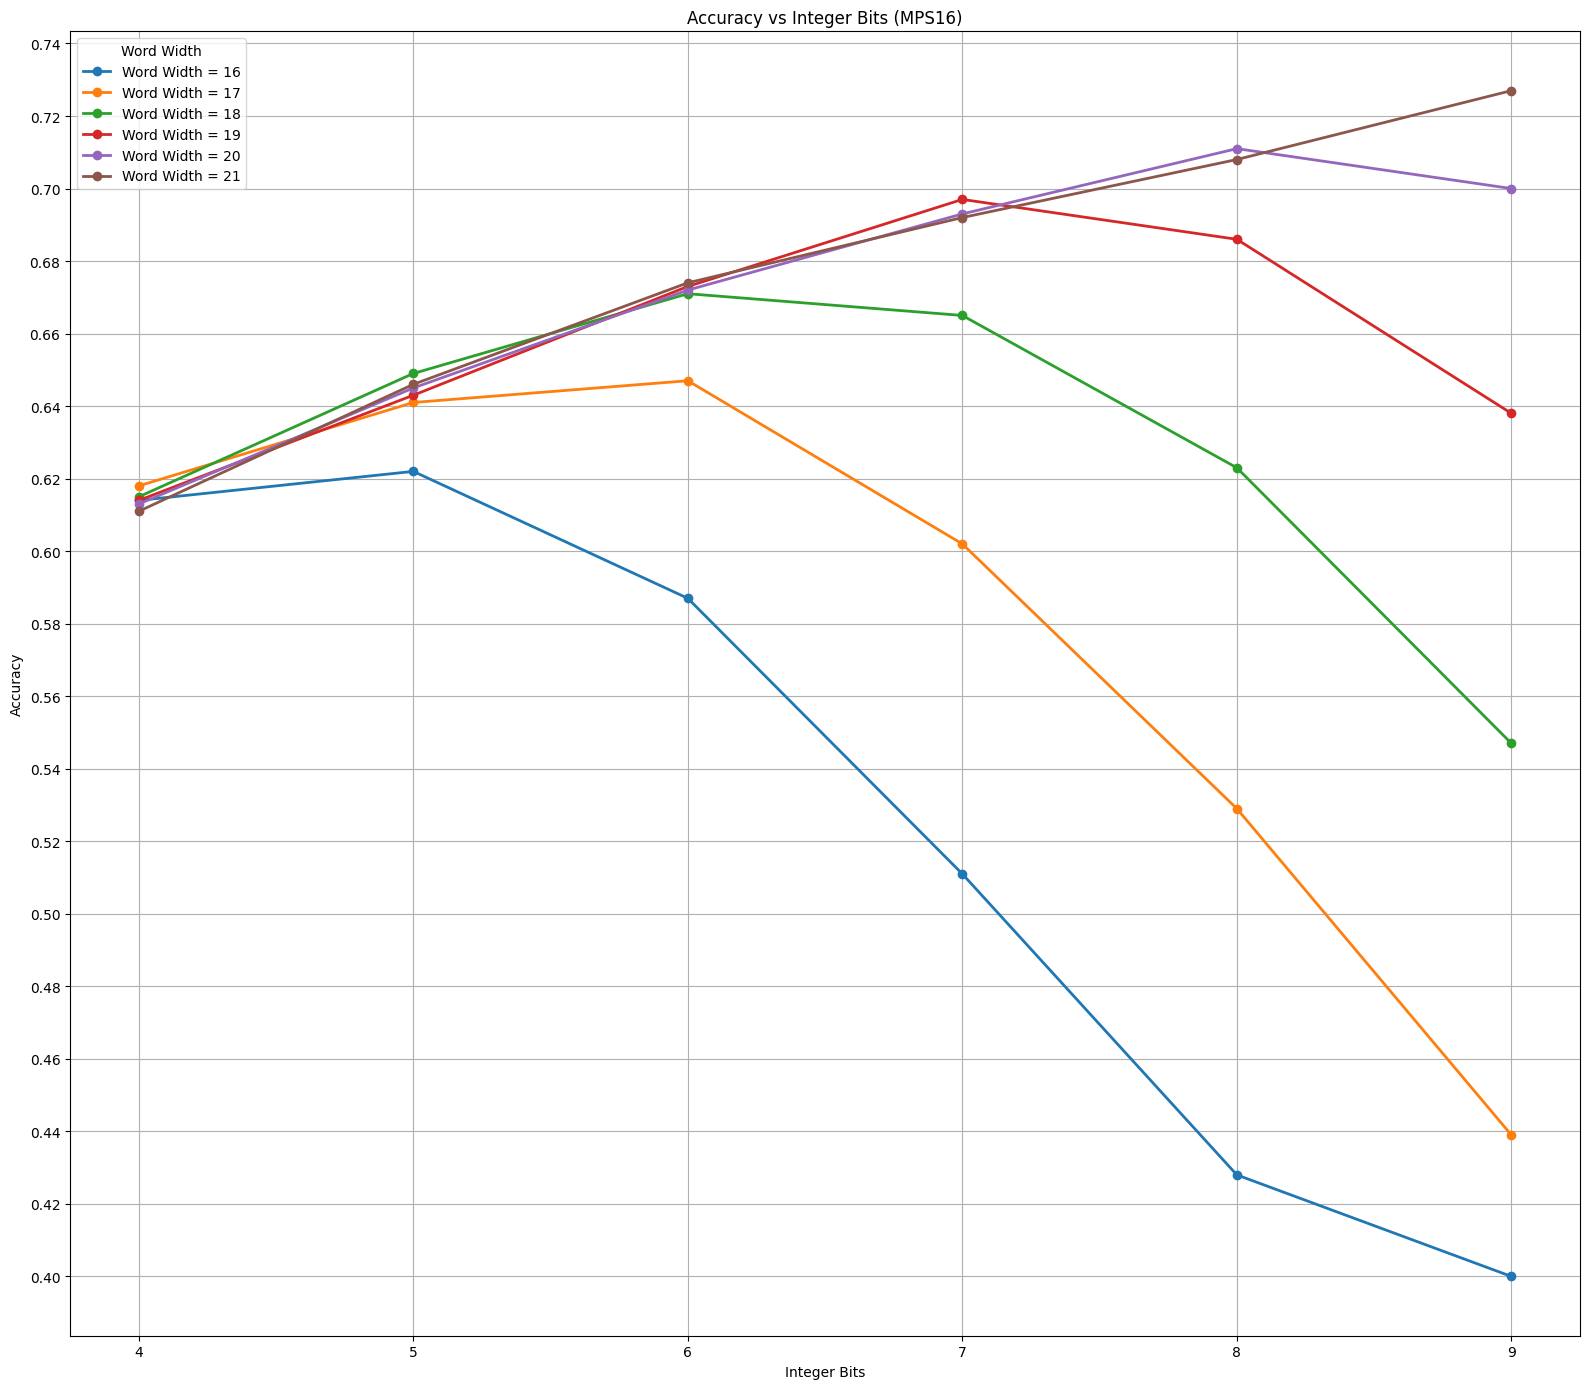

In [11]:
plot_accuracy_vs_integer_bits(ww_list, iw_list, accuracy_list, dataset_name="MPS16")

## MPS4

In [80]:
mps4_quantization_folder = Path("./mps4_qresults")
mps4_results_list = list(mps4_quantization_folder.glob("*.txt"))
mps4_results_list.sort()

In [22]:
ww_list = []
iw_list = []
accuracy_list = []
mps4_labels_file = Path("./datasets/mps_data/y_N4.npy")
for results_file in mps4_results_list:
    word_width, int_bits, accuracy = calc_accuracy(results_file, mps4_labels_file)
    ww_list.append(word_width)
    iw_list.append(int_bits)
    accuracy_list.append(accuracy)
    print(f"Accuracy for {word_width}_{int_bits}: {accuracy:.4f}")

Accuracy for 16_4: 0.7010
Accuracy for 16_5: 0.7260
Accuracy for 16_6: 0.7340
Accuracy for 16_7: 0.7110
Accuracy for 16_8: 0.6240
Accuracy for 16_9: 0.5670
Accuracy for 17_4: 0.7020
Accuracy for 17_5: 0.7310
Accuracy for 17_6: 0.7330
Accuracy for 17_7: 0.7380
Accuracy for 17_8: 0.7130
Accuracy for 17_9: 0.6250
Accuracy for 18_4: 0.7010
Accuracy for 18_5: 0.7320
Accuracy for 18_6: 0.7380
Accuracy for 18_7: 0.7370
Accuracy for 18_8: 0.7390
Accuracy for 18_9: 0.7140
Accuracy for 19_4: 0.7010
Accuracy for 19_5: 0.7310
Accuracy for 19_6: 0.7390
Accuracy for 19_7: 0.7420
Accuracy for 19_8: 0.7380
Accuracy for 19_9: 0.7400
Accuracy for 20_4: 0.7010
Accuracy for 20_5: 0.7310
Accuracy for 20_6: 0.7380
Accuracy for 20_7: 0.7430
Accuracy for 20_8: 0.7430
Accuracy for 20_9: 0.7390
Accuracy for 21_4: 0.7010
Accuracy for 21_5: 0.7310
Accuracy for 21_6: 0.7380
Accuracy for 21_7: 0.7420
Accuracy for 21_8: 0.7440
Accuracy for 21_9: 0.7440


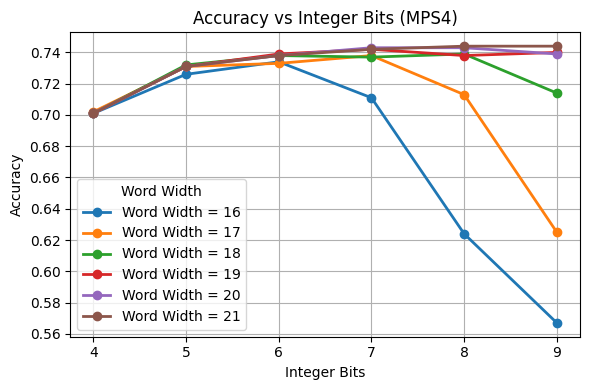

In [23]:
plot_accuracy_vs_integer_bits(ww_list, iw_list, accuracy_list, dataset_name="MPS4")

## DSP Usage

In [20]:
import pandas as pd
from pandas import DataFrame as df
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from collections import defaultdict




   wordwidth  intwidth  dsp  dsppercentage
0         16         4  561             10
1         16         5  533              9
2         16         6  471              8
3         16         7  402              7
4         16         8  331              5


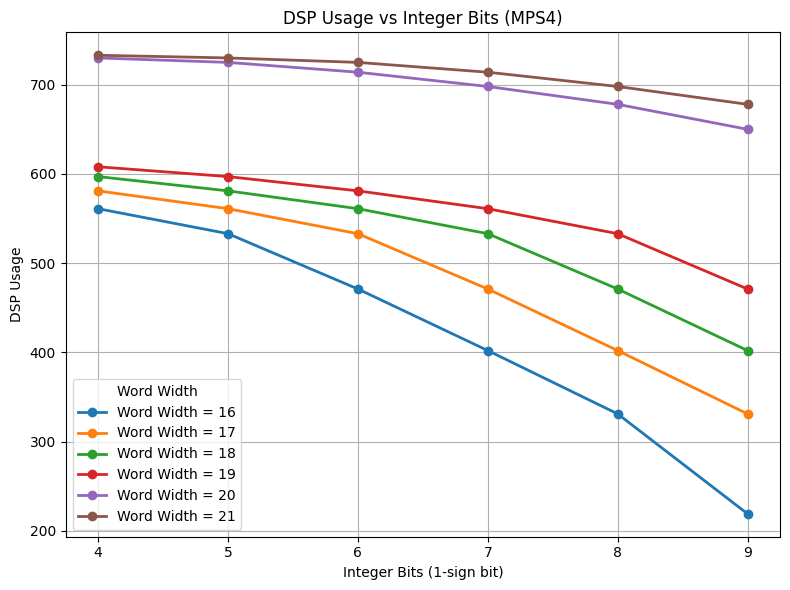

In [41]:

def plot_dsp_vs_integer_bits(ww_list, iw_list, dsp_list, dataset_name="MPS16"):
    # Group data by word width
    data = defaultdict(lambda: {"int": [], "dsp": []})

    for w, i, a in zip(ww_list, iw_list, dsp_list):
        data[w]["int"].append(i)
        data[w]["dsp"].append(a)

    # Plot
    plt.figure(figsize=(8,6))

    for w in sorted(data.keys()):
        # Sort by integer bits so the line is drawn correctly
        x, y = zip(*sorted(zip(data[w]["int"], data[w]["dsp"])))
        plt.plot(x, y, marker='o', linewidth=2, label=f'Word Width = {w}')

    ax = plt.gca()
    # ax.yaxis.set_major_locator(MultipleLocator(100))
    if max(dsp_list) > 5520:
        plt.axhline(5520, linestyle='--', color='red', label='DSP Limit (5520)')
        
    plt.xlabel("Integer Bits (1-sign bit)")
    plt.ylabel("DSP Usage")
    # plt.yticks(dsp_list)
    plt.title(f"DSP Usage vs Integer Bits ({dataset_name})")
    plt.grid(True)
    plt.legend(title="Word Width")
    plt.tight_layout()
    plt.show()
    

df = pd.read_csv("mps4_dsp.txt")
print(df.head())
plot_dsp_vs_integer_bits(df['wordwidth'].tolist(), df['intwidth'].tolist(), df['dsp'].tolist(), dataset_name="MPS4")

   wordwidth  intwidth   dsp  dsppercentage
0         16         4  4776             86
1         16         5  4326             78
2         16         6  3738             67
3         16         7  2951             53
4         16         8  2161             39


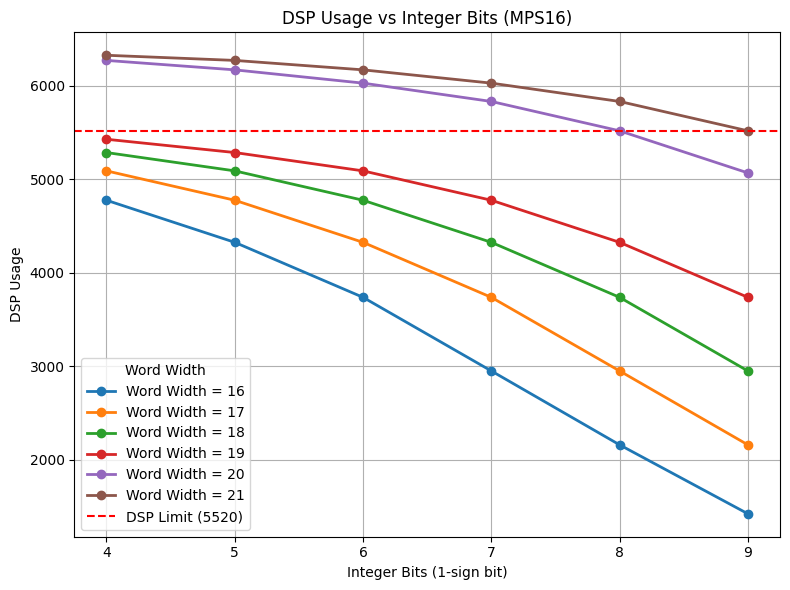

In [42]:
df = pd.read_csv("mps16_dsp.txt")
print(df.head())
plot_dsp_vs_integer_bits(df['wordwidth'].tolist(), df['intwidth'].tolist(), df['dsp'].tolist(), dataset_name="MPS16")

## MPS4 Normalized

In [24]:
mps4_quantization_folder = Path("./mps4_normalized_qresults")
mps4_results_list = list(mps4_quantization_folder.glob("*.txt"))
mps4_results_list.sort()

In [25]:
ww_list = []
iw_list = []
accuracy_list = []
mps4_labels_file = Path("./datasets/mps_data/y_N4.npy")
for results_file in mps4_results_list:
    word_width, int_bits, accuracy = calc_accuracy(results_file, mps4_labels_file)
    ww_list.append(word_width)
    iw_list.append(int_bits)
    accuracy_list.append(accuracy)
    print(f"Accuracy for {word_width}_{int_bits}: {accuracy:.4f}")

Accuracy for 16_3: 0.4060
Accuracy for 16_4: 0.4430
Accuracy for 16_5: 0.4640
Accuracy for 16_6: 0.4420
Accuracy for 17_3: 0.4380
Accuracy for 17_4: 0.4810
Accuracy for 17_5: 0.4570
Accuracy for 17_6: 0.4660
Accuracy for 18_3: 0.5070
Accuracy for 18_4: 0.5130
Accuracy for 18_5: 0.4950
Accuracy for 18_6: 0.4590
Accuracy for 19_3: 0.5810
Accuracy for 19_4: 0.5840
Accuracy for 19_5: 0.5280
Accuracy for 19_6: 0.4970
Accuracy for 20_3: 0.6290
Accuracy for 20_4: 0.6570
Accuracy for 20_5: 0.5980
Accuracy for 20_6: 0.5300
Accuracy for 21_3: 0.6440
Accuracy for 21_4: 0.7050
Accuracy for 21_5: 0.6710
Accuracy for 21_6: 0.6000


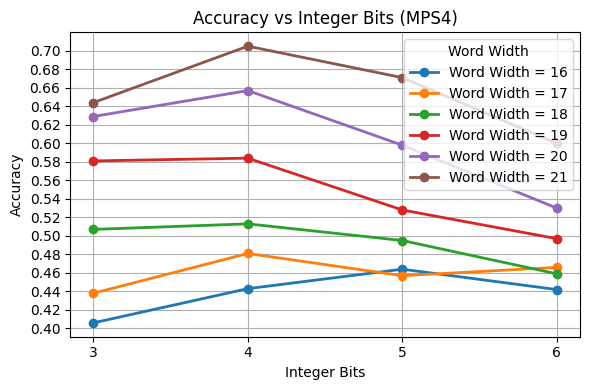

In [26]:
plot_accuracy_vs_integer_bits(ww_list, iw_list, accuracy_list, dataset_name="MPS4")


In [34]:
n16 = np.load('outputs_N16_nmps.npy')
n16

array([[ 2.15503091e-17,  2.75377882e-17, -3.24412372e-17,
        -1.06218229e-17, -1.03013532e-17],
       [-1.00479670e-16,  2.19091319e-16, -9.47410211e-17,
        -2.03046267e-17, -4.03014926e-18],
       [ 1.86022719e-18, -1.12714329e-17,  4.76493794e-17,
        -2.03607546e-17, -1.89286726e-17],
       ...,
       [ 3.52661737e-17, -1.10589119e-17,  1.95397032e-17,
        -2.64095730e-17, -1.77568821e-17],
       [-2.22897002e-17,  8.01844849e-17, -3.15000862e-17,
        -1.70375885e-17, -9.85978144e-18],
       [-1.11532777e-15,  5.43038832e-15, -2.44598301e-15,
        -1.06345610e-15, -1.29535996e-15]])

In [55]:
X = n16[0][0]
'{:.18}'.format(str(X))

'2.155030905855191e'

In [58]:
print(f'{X:.17f}')

0.00000000000000002


## MPS4 Long Sweep

In [17]:
mps4_quantization_folder = Path("./mps4_long_sweep_qresults")
mps4_results_list = list(mps4_quantization_folder.glob("*.txt"))
# mps4_results_list

In [18]:
ww_list = []
iw_list = []
accuracy_list = []
mps4_labels_file = Path("./datasets/mps_data/y_N4.npy")
for results_file in mps4_results_list:
    word_width, int_bits, accuracy = calc_accuracy(results_file, mps4_labels_file)
    if word_width < 28:
        continue
    ww_list.append(word_width)
    iw_list.append(int_bits)
    accuracy_list.append(accuracy)
    print(f"Accuracy for {word_width}_{int_bits}: {accuracy:.4f}")

Accuracy for 28_4: 0.7010
Accuracy for 28_5: 0.7310
Accuracy for 28_6: 0.7380
Accuracy for 28_7: 0.7420
Accuracy for 28_8: 0.7430
Accuracy for 28_9: 0.7440
Accuracy for 28_10: 0.7440
Accuracy for 28_11: 0.7440
Accuracy for 28_12: 0.7440
Accuracy for 28_13: 0.7440
Accuracy for 28_14: 0.7440
Accuracy for 28_15: 0.7450
Accuracy for 28_16: 0.7440
Accuracy for 28_17: 0.7390
Accuracy for 28_18: 0.7400
Accuracy for 28_19: 0.7140
Accuracy for 28_20: 0.6250
Accuracy for 28_21: 0.5670
Accuracy for 28_22: 0.5100
Accuracy for 28_23: 0.4620
Accuracy for 28_24: 0.3960
Accuracy for 29_4: 0.7010
Accuracy for 29_5: 0.7310
Accuracy for 29_6: 0.7380
Accuracy for 29_7: 0.7420
Accuracy for 29_8: 0.7430
Accuracy for 29_9: 0.7440
Accuracy for 29_10: 0.7440
Accuracy for 29_11: 0.7440
Accuracy for 29_12: 0.7440
Accuracy for 29_13: 0.7440
Accuracy for 29_14: 0.7440
Accuracy for 29_15: 0.7440
Accuracy for 29_16: 0.7450
Accuracy for 29_17: 0.7440
Accuracy for 29_18: 0.7390
Accuracy for 29_19: 0.7400
Accuracy for 

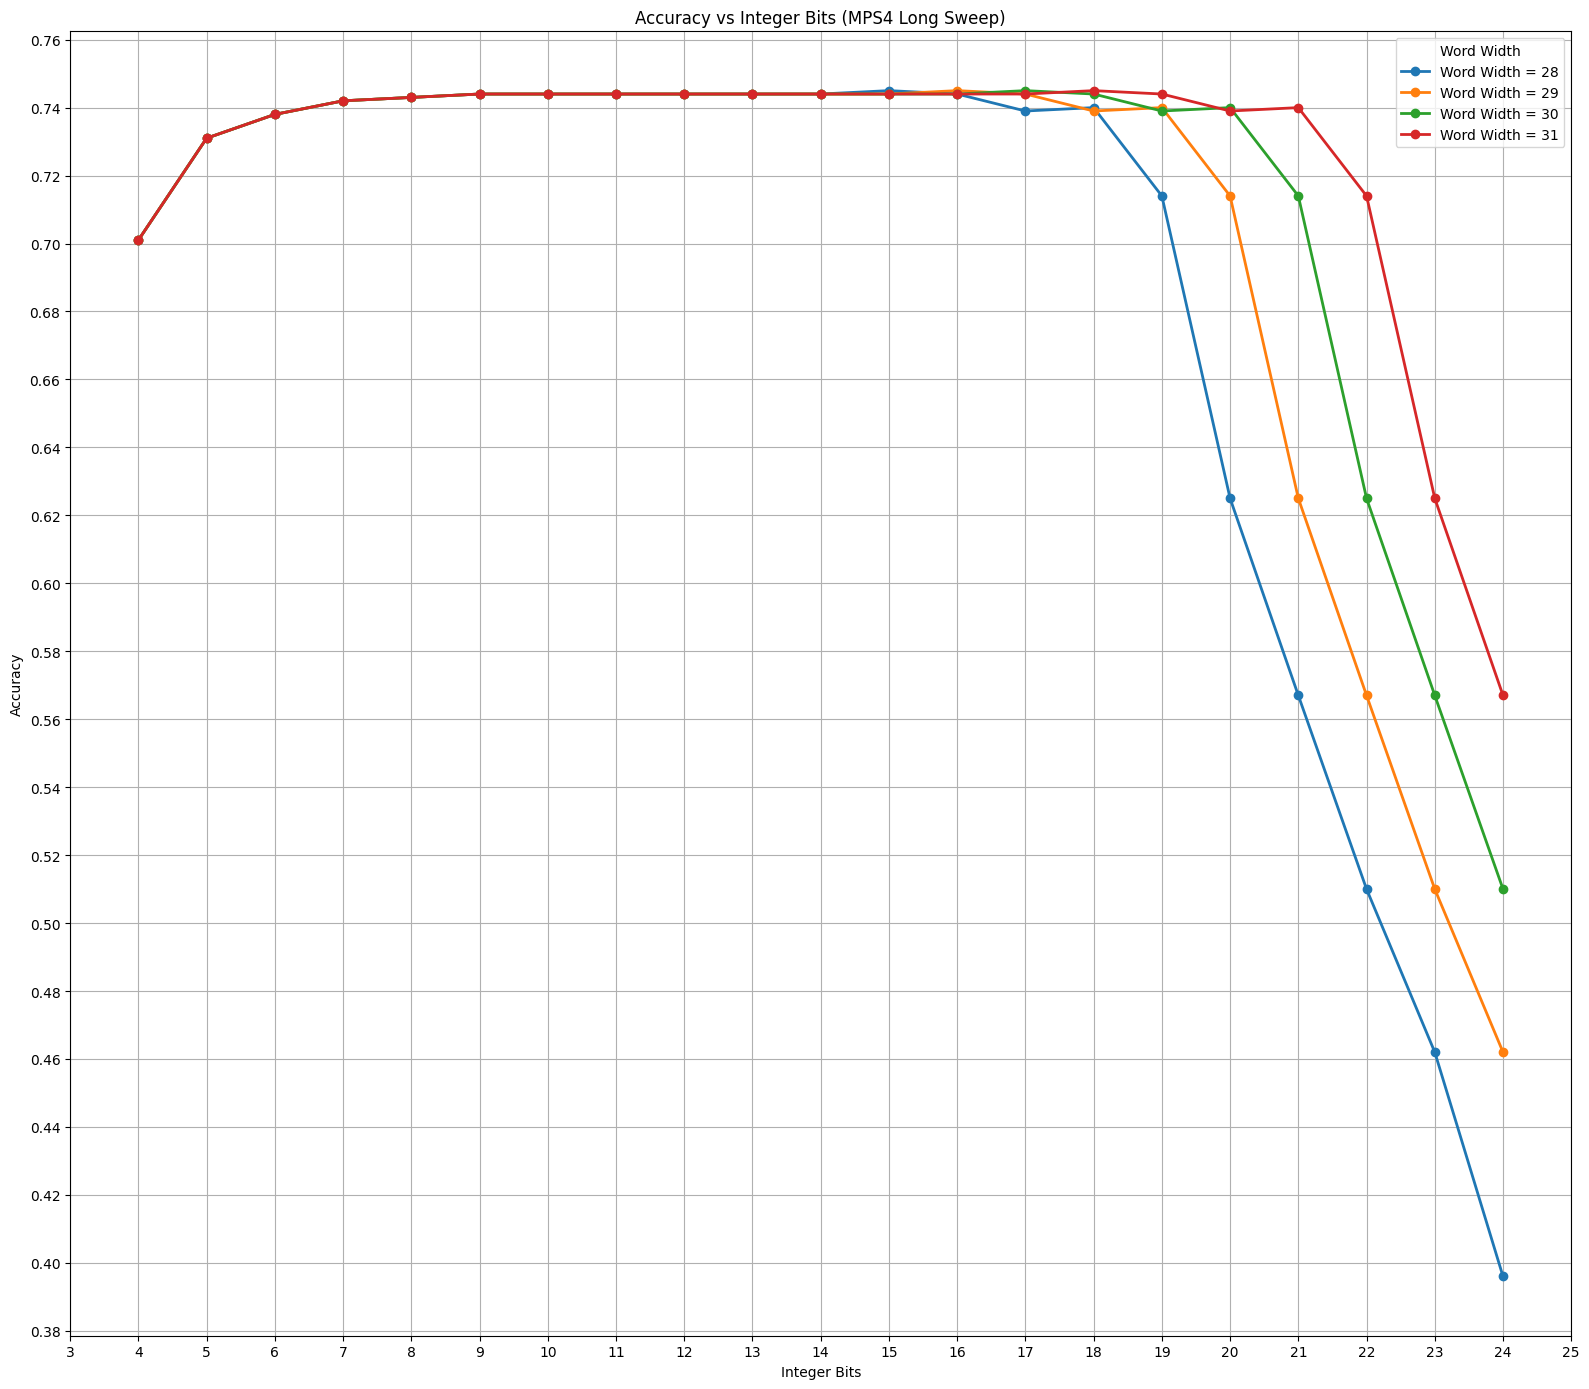

In [19]:
plot_accuracy_vs_integer_bits(ww_list, iw_list, accuracy_list, dataset_name="MPS4 Long Sweep")

## MPS16 Long Sweep

In [12]:
mps16_quantization_folder = Path("./qresults")
# mps16_quantization_folder = Path("./mps16_long_sweep_qresults")
mps16_results_list = list(mps16_quantization_folder.glob("*.txt"))

In [15]:
ww_list = []
iw_list = []
accuracy_list = []
mps16_labels_file = Path("./datasets/mps_data/y_N16.npy")
for results_file in mps16_results_list:
    word_width, int_bits, accuracy = calc_accuracy(results_file, mps16_labels_file)
    ww_list.append(word_width)
    iw_list.append(int_bits)
    accuracy_list.append(accuracy)
    print(f"Accuracy for {word_width}_{int_bits}: {accuracy:.4f}")

Accuracy for 22_4: 0.6110
Accuracy for 22_5: 0.6460
Accuracy for 22_6: 0.6740
Accuracy for 22_7: 0.6960
Accuracy for 22_8: 0.7090
Accuracy for 22_9: 0.7250
Accuracy for 23_4: 0.6110
Accuracy for 23_5: 0.6460
Accuracy for 23_6: 0.6750
Accuracy for 23_7: 0.6990
Accuracy for 23_8: 0.7100
Accuracy for 23_9: 0.7260
Accuracy for 24_4: 0.6110
Accuracy for 24_5: 0.6460
Accuracy for 24_6: 0.6770
Accuracy for 24_7: 0.7010
Accuracy for 24_8: 0.7110
Accuracy for 24_9: 0.7270
Accuracy for 25_4: 0.6110
Accuracy for 25_5: 0.6470
Accuracy for 25_6: 0.6770
Accuracy for 25_7: 0.6990
Accuracy for 25_8: 0.7120
Accuracy for 25_9: 0.7270
Accuracy for 26_4: 0.6110
Accuracy for 26_5: 0.6470
Accuracy for 26_6: 0.6770
Accuracy for 26_7: 0.6970
Accuracy for 26_8: 0.7120
Accuracy for 26_9: 0.7270
Accuracy for 27_4: 0.6100
Accuracy for 27_5: 0.6470
Accuracy for 27_6: 0.6770
Accuracy for 27_7: 0.6970
Accuracy for 27_8: 0.7120
Accuracy for 27_9: 0.7280
Accuracy for 22_10: 0.7330
Accuracy for 22_11: 0.7180
Accuracy f

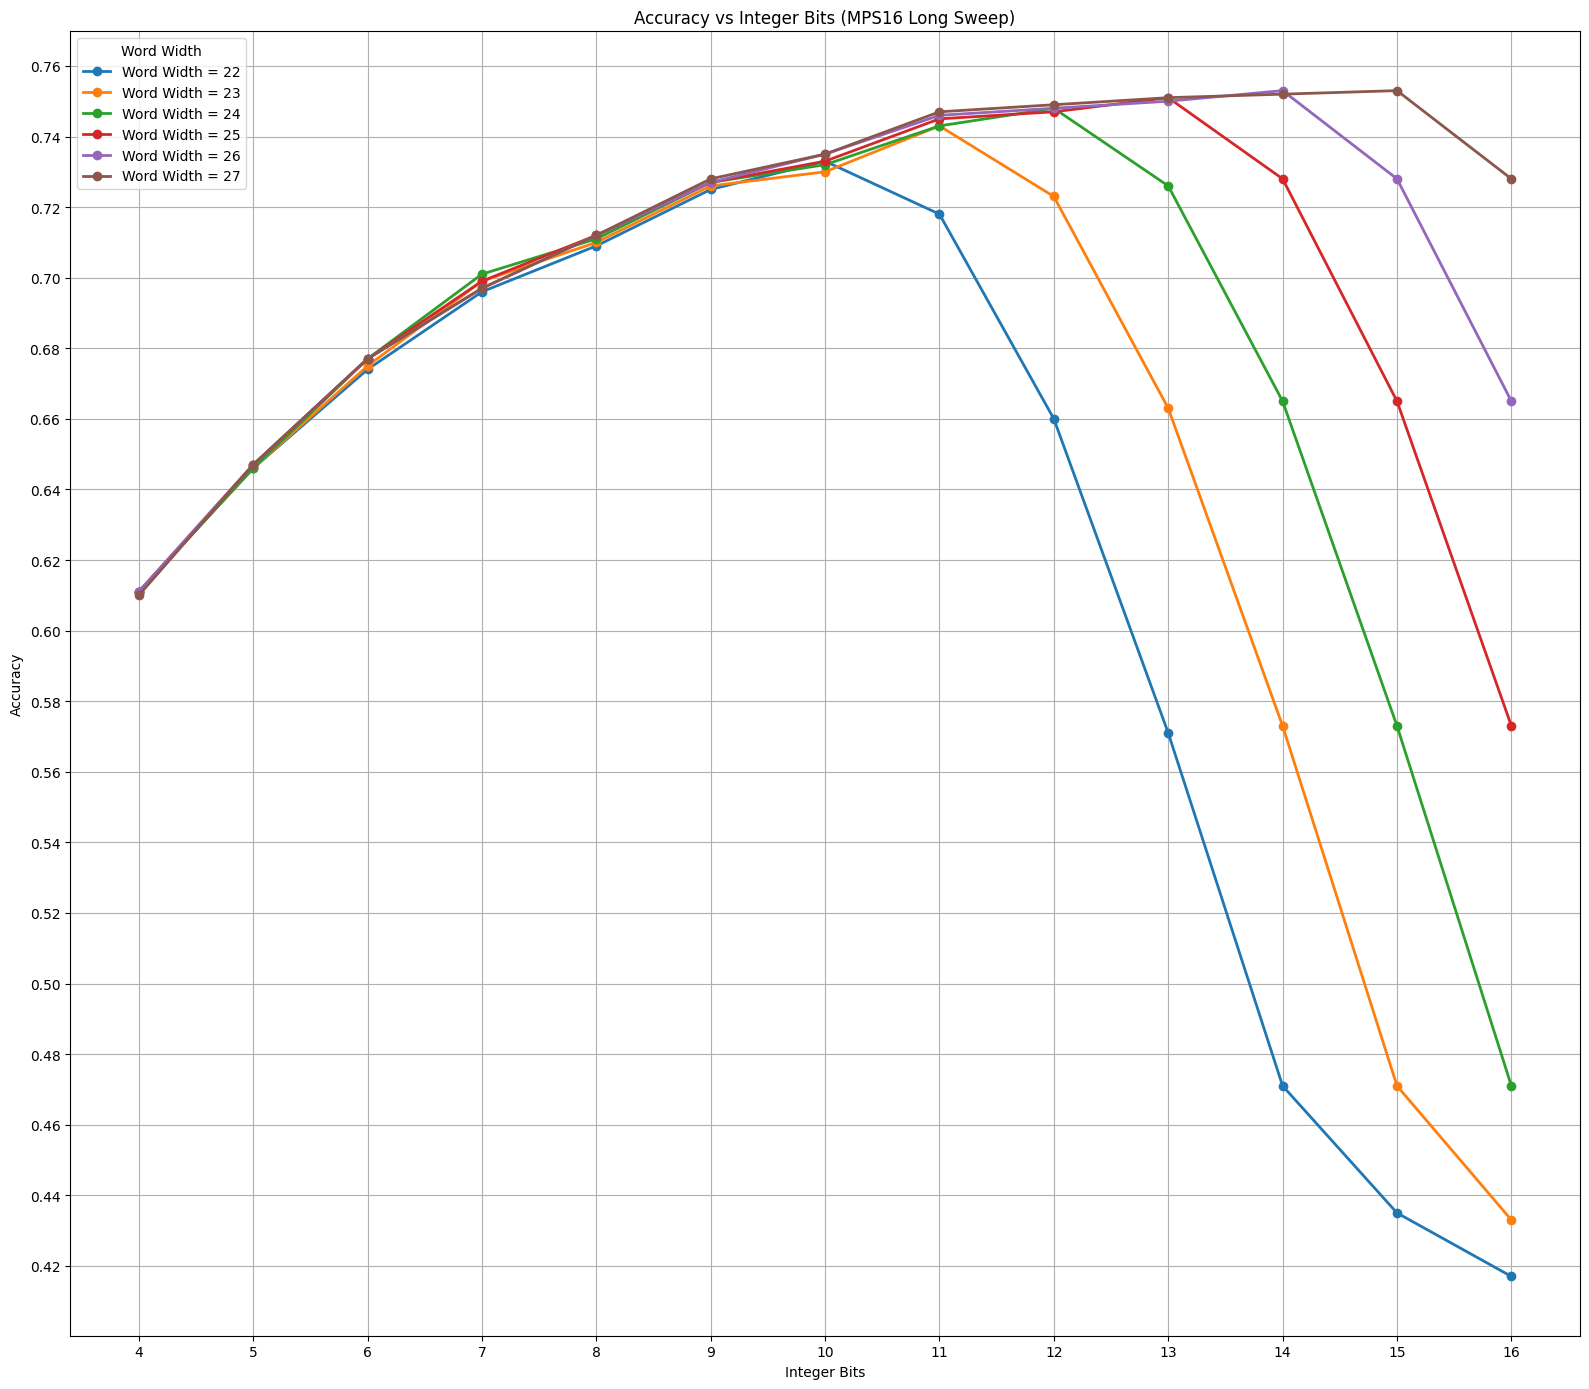

In [16]:
plot_accuracy_vs_integer_bits(ww_list, iw_list, accuracy_list, dataset_name="MPS16 Long Sweep")

## Symm TTN sweep

In [20]:
ttns_quantization_folder = Path("./qresults")
# mps16_quantization_folder = Path("./mps16_long_sweep_qresults")
ttns_results_list = list(ttns_quantization_folder.glob("*.txt"))

In [29]:
ww_list = []
iw_list = []
accuracy_list = []
ttns_labels_file = Path("./datasets/set2/y_train_true.npy")
for results_file in ttns_results_list:
    word_width, int_bits, accuracy = calc_accuracy(results_file, ttns_labels_file, sample_size=800)
    ww_list.append(word_width)
    iw_list.append(int_bits)
    accuracy_list.append(accuracy)
    print(f"Accuracy for {word_width}_{int_bits}: {accuracy:.4f}")

Predictions shape: (800, 5), True labels shape: (644264, 5)
Accuracy for 16_4: 0.0850
Predictions shape: (800, 5), True labels shape: (644264, 5)
Accuracy for 16_2: 0.0862
Predictions shape: (800, 5), True labels shape: (644264, 5)
Accuracy for 16_3: 0.0850
Predictions shape: (800, 5), True labels shape: (644264, 5)
Accuracy for 16_5: 0.0900
Predictions shape: (800, 5), True labels shape: (644264, 5)
Accuracy for 17_2: 0.0875
Predictions shape: (800, 5), True labels shape: (644264, 5)
Accuracy for 17_3: 0.0850
Predictions shape: (800, 5), True labels shape: (644264, 5)
Accuracy for 17_4: 0.0850
Predictions shape: (800, 5), True labels shape: (644264, 5)
Accuracy for 17_5: 0.0850
Predictions shape: (800, 5), True labels shape: (644264, 5)
Accuracy for 18_2: 0.0862
Predictions shape: (800, 5), True labels shape: (644264, 5)
Accuracy for 18_3: 0.0862
Predictions shape: (800, 5), True labels shape: (644264, 5)
Accuracy for 18_4: 0.0850
Predictions shape: (800, 5), True labels shape: (64426